# 08 · Exploratory high-recall review policy and the missed cases

At its original, frozen threshold (0.086) the LightGBM model caught 86 of the 101 labelled providers in the held-out test and missed 15. Knowing that result, the team is exploring a higher-recall review policy. This notebook does that **without changing the model or the original final evaluation**, and analyses the misses.

**What this notebook can and cannot show.** The held-out test set has already been used, and its result motivated this exploration. Nothing here can create a fresh, independent test. Section 4 is a **supplementary evaluation on the previously used test set**; the original result stays the project's final evaluation.

**Order, enforced by the notebook:**

| Section | Data used | Purpose |
|---|---|---|
| 1. Compare policies | Validation (out-of-fold) only | Workload and fold-by-fold variation for 80%, 90% and 95% recall targets, plus a cross-check against the earlier comparison |
| 2. Validation misses | Validation only | Which kinds of provider the model misses; may inform the choice and later model work |
| 3. Commit | Validation only | Record the chosen target, decision-makers and rationale. Stops here if not filled in |
| *(git commit)* | | Commit the policy file to git before continuing; Section 4 checks this |
| 4. Supplementary evaluation | Test labels, once | Evaluate the committed policy on the previously used test set |
| 5. The 15 original misses | Test set, descriptive | Which the policy recovers, which remain, at what added review burden |

"Run All" with the decision settings blank stops at Section 3, before any test data is read.

**Nothing frozen is modified.** `selected_metadata.json`, `final_model_selection.json` and the original test results are untouched. The policy has its own file.

In [1]:
import json
import subprocess
import sys
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append("..")
from dashboard import core, glossary   # same loader, checks and explanations as the dashboard

pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.max_colwidth", 80)

bundle = core.load_bundle()            # verifies the run against final_model_selection.json
meta = bundle.meta
RUN_DIR = bundle.run_dir
SHARED = Path("../artifacts/shared")
POLICY_PATH = SHARED / "exploratory_review_policy.json"
EVAL_PATH = SHARED / "exploratory_policy_supplementary_evaluation.json"
REPORT_DIR = Path("../reports/error_analysis")
ORIGINAL_THRESHOLD = bundle.threshold
TARGETS = [0.80, 0.90, 0.95]
SEED = 4012
N_BOOT = 2000
CONTEXT = [f for f in ["NumClaims", "PropInpatient", "AvgClaimAmt", "MaxClaimAmt", "AvgClaimsPerBeneficiary",
                       "AvgLengthOfStayDays", "TopProcedureCodeShareMissing", "BenfordMADMissing"] if f in bundle.features]

oof_all = pd.read_csv(RUN_DIR / "oof_predictions.csv")
oof = oof_all[(oof_all["model"] == meta["model"]) & (oof_all["strategy"] == meta["strategy"])].reset_index(drop=True)
y_val, p_val, fold = oof["y_true"].to_numpy(), oof["oof_prob"].to_numpy(), oof["fold"].to_numpy()
FOLDS = sorted(np.unique(fold))

print(f"Run {bundle.run_id}: {bundle.model_name}, {bundle.strategy_name}; original threshold {ORIGINAL_THRESHOLD:.6f}")
print(f"Validation: {len(oof):,} training providers, {int(y_val.sum())} labelled positive, {len(FOLDS)} folds")

Run 20261011_232303_full: LightGBM, original class balance; original threshold 0.086105
Validation: 4,328 training providers, 405 labelled positive, 5 folds


## 1. Compare policies (validation only)

Each threshold uses the rule from notebook 06b: **among thresholds whose out-of-fold recall meets the target, choose the one with the highest precision.** The 80% row must reproduce the frozen threshold exactly.

In [2]:
def threshold_for_recall(y, p, target):
    # Same rule as 06b: highest precision among thresholds with recall >= target.
    from sklearn.metrics import precision_recall_curve
    prec, rec, thr = precision_recall_curve(y, p)
    prec, rec = prec[:-1], rec[:-1]
    ok = rec >= target
    if not ok.any():
        raise ValueError(f"No threshold reaches recall {target}")
    return float(thr[int(np.argmax(np.where(ok, prec, -1)))])


def outcome(y, p, t):
    flagged = p >= t
    tp, fp = int((flagged & (y == 1)).sum()), int((flagged & (y == 0)).sum())
    fn, tn = int((~flagged & (y == 1)).sum()), int((~flagged & (y == 0)).sum())
    return {"threshold": t, "caught": tp, "missed": fn, "reviewed": tp + fp, "share_reviewed": (tp + fp) / len(y),
            "recall": tp / max(tp + fn, 1), "precision": tp / max(tp + fp, 1), "false_alerts": fp, "tn": tn}


thresholds = {t: threshold_for_recall(y_val, p_val, t) for t in TARGETS}
assert abs(thresholds[0.80] - ORIGINAL_THRESHOLD) < 1e-12, "The 80% target does not reproduce the frozen threshold"
print("The 80% target reproduces the frozen threshold exactly.")

policies = pd.DataFrame([{"target": f"{t:.0%}", **outcome(y_val, p_val, thr)} for t, thr in thresholds.items()])
base = policies.iloc[0]
policies["extra_reviews_vs_80"] = policies["reviewed"] - base["reviewed"]
policies["extra_caught_vs_80"] = policies["caught"] - base["caught"]
policies["reviews_per_extra_catch"] = (policies["extra_reviews_vs_80"] / policies["extra_caught_vs_80"]).where(
    policies["extra_caught_vs_80"] > 0)
policies[["target", "threshold", "caught", "missed", "reviewed", "share_reviewed", "precision",
          "extra_reviews_vs_80", "extra_caught_vs_80", "reviews_per_extra_catch"]]

The 80% target reproduces the frozen threshold exactly.


,target,threshold,caught,missed,reviewed,share_reviewed,precision,extra_reviews_vs_80,extra_caught_vs_80,reviews_per_extra_catch
0,80%,0.0861,324,81,701,0.1620,0.4622,0,0,NaN
1,90%,0.0241,365,40,1036,0.2394,0.3523,335,41,8.1707
2,95%,0.0069,385,20,1422,0.3286,0.2707,721,61,11.8197


In [3]:
# Cross-check against the comparison computed earlier, before anything is committed.
# If this fails, the files differ from the ones that comparison used: investigate before deciding.
EARLIER_COMPARISON = {
    0.80: {"caught": 324, "reviewed": 701},
    0.90: {"caught": 365, "reviewed": 1036},
    0.95: {"caught": 385, "reviewed": 1422, "threshold": 0.006877851788421944},
}
mismatches = []
for t, expected in EARLIER_COMPARISON.items():
    got = outcome(y_val, p_val, thresholds[t])
    for k, v in expected.items():
        if (abs(got[k] - v) > 1e-12) if k == "threshold" else (got[k] != v):
            mismatches.append(f"{t:.0%} {k}: earlier {v}, now {got[k]}")
if mismatches:
    raise ValueError("Validation results differ from the earlier comparison: " + "; ".join(mismatches))
print("Matches the earlier 80% / 90% / 95% comparison exactly.")

Matches the earlier 80% / 90% / 95% comparison exactly.


In [4]:
# (a) Variation across folds at the pooled threshold. DESCRIPTIVE ONLY: every fold's labels helped choose the threshold.
rows = []
for t, thr in thresholds.items():
    for k in FOLDS:
        m = fold == k
        o = outcome(y_val[m], p_val[m], thr)
        rows.append({"target": f"{t:.0%}", "fold": int(k), "recall": o["recall"], "precision": o["precision"],
                     "share_reviewed": o["share_reviewed"], "missed": o["missed"]})
by_fold = pd.DataFrame(rows)

# (b) Leave-one-fold-out threshold: choose the threshold on the other folds' predictions, then measure the held-out fold.
#     The threshold choice no longer sees that fold's labels. Not fully nested: the other folds' scores came from models
#     that were trained partly on the held-out fold, so this is still optimistic. A full check needs nested model training.
rows = []
for t in TARGETS:
    for k in FOLDS:
        inner = fold != k
        thr_k = threshold_for_recall(y_val[inner], p_val[inner], t)
        o = outcome(y_val[~inner], p_val[~inner], thr_k)
        rows.append({"target": f"{t:.0%}", "fold": int(k), "threshold_without_this_fold": thr_k,
                     "recall": o["recall"], "share_reviewed": o["share_reviewed"]})
lofo = pd.DataFrame(rows)

summary = pd.DataFrame({
    "pooled threshold: recall min": by_fold.groupby("target", sort=False)["recall"].min(),
    "pooled threshold: recall max": by_fold.groupby("target", sort=False)["recall"].max(),
    "fold left out of choice: recall min": lofo.groupby("target", sort=False)["recall"].min(),
    "fold left out of choice: recall max": lofo.groupby("target", sort=False)["recall"].max(),
    "fold left out of choice: recall mean": lofo.groupby("target", sort=False)["recall"].mean(),
    "share reviewed min": lofo.groupby("target", sort=False)["share_reviewed"].min(),
    "share reviewed max": lofo.groupby("target", sort=False)["share_reviewed"].max(),
})
display(lofo.pivot(index="fold", columns="target", values="recall").rename_axis(columns="recall, threshold chosen without this fold"))
summary

"recall, threshold chosen without this fold",80%,90%,95%
fold,,,
0,0.7778,0.9012,0.9259
1,0.8025,0.8765,0.9383
2,0.8272,0.8889,0.9506
3,0.7778,0.8642,0.9630
4,0.8395,0.9506,0.9630


,pooled threshold: recall min,pooled threshold: recall max,fold left out of choice: recall min,fold left out of choice: recall max,fold left out of choice: recall mean,share reviewed min,share reviewed max
target,,,,,,,
80%,0.7778,0.8272,0.7778,0.8395,0.8049,0.1536,0.1734
90%,0.8765,0.9383,0.8642,0.9506,0.8963,0.2206,0.2532
95%,0.9383,0.9630,0.9259,0.9630,0.9481,0.2956,0.3318


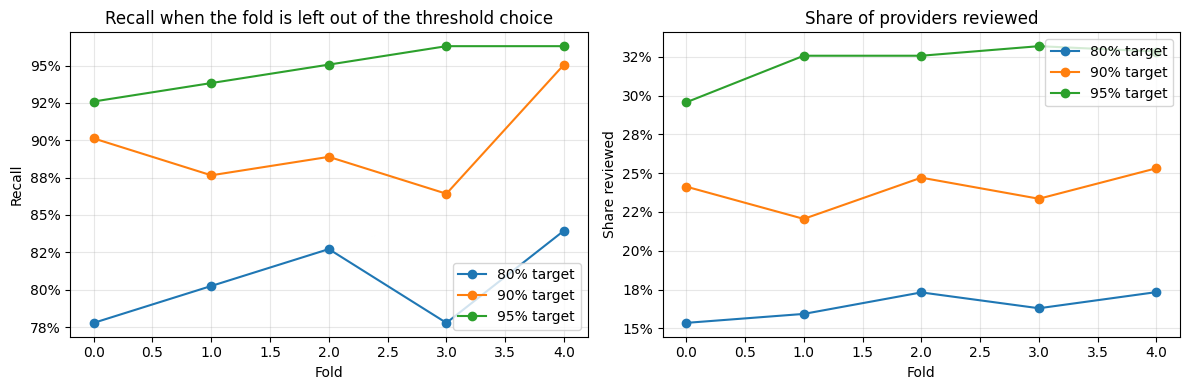

,target,threshold,positives_below,recall_if_threshold_x0.8,recall_if_threshold_x1.25
0,80%,0.0861,81,0.8198,0.7802
1,90%,0.0241,40,0.9111,0.8815
2,95%,0.0069,20,0.9580,0.9457


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for t in policies["target"]:
    d = lofo[lofo["target"] == t]
    axes[0].plot(d["fold"], d["recall"], "o-", label=f"{t} target")
    axes[1].plot(d["fold"], d["share_reviewed"], "o-", label=f"{t} target")
axes[0].set_title("Recall when the fold is left out of the threshold choice")
axes[1].set_title("Share of providers reviewed")
for ax, lab in zip(axes, ["Recall", "Share reviewed"]):
    ax.set_xlabel("Fold"); ax.set_ylabel(lab); ax.legend(); ax.grid(alpha=0.3)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout(); plt.show()

# How many positives set each threshold, and how much a small shift moves recall
pos_scores = p_val[y_val == 1]
pd.DataFrame([{"target": f"{t:.0%}", "threshold": thr,
               "positives_below": int((pos_scores < thr).sum()),
               "recall_if_threshold_x0.8": outcome(y_val, p_val, thr * 0.8)["recall"],
               "recall_if_threshold_x1.25": outcome(y_val, p_val, thr * 1.25)["recall"]}
              for t, thr in thresholds.items()])

**Reading Section 1.** Workload (`share_reviewed`, `reviews_per_extra_catch`) is the cost of each target. The leave-one-fold-out recall shows how much a target's recall varies when the threshold is chosen without the fold it is measured on. It is the better guide of the two fold tables, but still optimistic, and neither guarantees future recall. Report a range, not just the pooled figure.

## 2. Validation misses (validation only)

Which kinds of provider does the model miss, at the original threshold and at each candidate target, and does that recur across folds? Because this uses validation data, it can inform the choice in Section 3 and later feature or model work. Compare claim volume and inpatient mix before reading anything into the other differences.

In [6]:
wanted = set(bundle.features)
train_X = pd.read_csv(core.resolve_path(meta["train_path"]), usecols=lambda c: c in wanted | {bundle.id_col},
                      dtype={bundle.id_col: str})
train_X = core.restore_missing(train_X, bundle.restore_cols)
val = oof.astype({bundle.id_col: str}).merge(train_X, on=bundle.id_col, how="left", validate="one_to_one")
assert val[bundle.features].notna().any(axis=1).all(), "Training features did not line up with the out-of-fold predictions"


def profile_table(frame, group_col, order):
    out = {}
    for f in CONTEXT:
        agg = frame.groupby(group_col)[f].mean() if glossary.unit(f) == "flag" else frame.groupby(group_col)[f].median()
        out[glossary.label(f) + (" (share Yes)" if glossary.unit(f) == "flag" else " (median)")] = agg
    table = pd.DataFrame(out).T.reindex(columns=[c for c in order if c in frame[group_col].unique()])
    table.columns = [f"{c} (n={int((frame[group_col] == c).sum())})" for c in table.columns]
    return table


# Use the 80% threshold exactly as computed from these out-of-fold scores (thresholds[0.80], the same value behind
# the policy table and Table 5). One labelled provider's score equals the threshold; comparing against the value
# loaded from metadata can differ in the last floating-point digit and wrongly count that provider as missed.
val["group"] = np.select([(val["y_true"] == 1) & (val["oof_prob"] >= thresholds[0.80]), val["y_true"] == 1],
                         ["Caught (label yes)", "Missed (label yes)"], default="Label no")
display(profile_table(val, "group", ["Missed (label yes)", "Caught (label yes)", "Label no"]))

misses_by_fold = pd.DataFrame({f"missed at {t:.0%} target": val[val["y_true"] == 1].groupby("fold")["oof_prob"].apply(
    lambda s, thr=thr: int((s < thr).sum())) for t, thr in thresholds.items()})
display(misses_by_fold)

REPORT_DIR.mkdir(parents=True, exist_ok=True)
val[val["group"] == "Missed (label yes)"].to_csv(REPORT_DIR / "validation_missed_cases.csv", index=False)
print(f"Saved validation misses to {REPORT_DIR / 'validation_missed_cases.csv'} for Swei's analysis")

,Missed (label yes) (n=81),Caught (label yes) (n=324),Label no (n=3923)
Number of claims (median),60.0000,197.0000,27.0000
Share of inpatient claims (median),0.1333,0.2567,0.0000
Average claim amount (median),1744.5161,2951.5980,332.1951
Largest claim amount (median),18000.0000,56000.0000,3300.0000
Claims per patient (median),1.1333,1.2086,1.0851
Length of stay (median),4.7368,5.6916,0.0000
No primary procedure codes (share Yes),0.2593,0.0617,0.6809
Benford deviation unavailable (share Yes),0.2099,0.0401,0.4191


,missed at 80% target,missed at 90% target,missed at 95% target
fold,,,
0,18,8,5
1,16,9,5
2,15,8,4
3,18,10,3
4,14,5,3


Saved validation misses to ../reports/error_analysis/validation_missed_cases.csv for Swei's analysis


## 3. Commit one policy

Fill in the three settings (target, decision-makers, rationale) and run the cell. It writes `artifacts/shared/exploratory_review_policy.json`, recording the exact threshold, target, model fingerprint, validation-prediction fingerprint, decision-makers, rationale and time. **If the settings are blank, the notebook stops here, before any test data is read.**

The file refuses to be overwritten, which guards against accidents, not against deliberate edits. The real record is git: **commit the policy file before running Section 4**, which checks that it is committed and unchanged:

```bash
git add artifacts/shared/exploratory_review_policy.json
git commit -m "Commit exploratory high-recall review policy (before supplementary test evaluation)"
```

In [7]:
CHOSEN_TARGET = 0.90
DECIDED_BY = "Pei and Swei"
RATIONALE = "Catches 90% of labelled providers in validation (365 of 405) with 24% of providers reviewed (1,036 of 4,328). With the threshold chosen without each fold, recall ranged from 86% to 95%. The 95% target would need 33% of providers reviewed (1,422) for 20 more catches, about 19 extra reviews per extra provider found, which we judged too costly."

if POLICY_PATH.exists():
    policy = json.loads(POLICY_PATH.read_text())
    print(f"Policy already committed on {policy['committed_at']} ({policy['target_recall']:.0%} target, threshold "
          f"{policy['threshold']:.6f}). It is not overwritten; changes to the settings above are ignored.")
else:
    if CHOSEN_TARGET is None or not DECIDED_BY.strip() or not RATIONALE.strip():
        raise RuntimeError("Stopping before any test data is read: set CHOSEN_TARGET, DECIDED_BY and RATIONALE, "
                           "then run this cell again.")
    assert CHOSEN_TARGET in (0.90, 0.95), "Choose 0.90 or 0.95"
    thr = threshold_for_recall(y_val, p_val, CHOSEN_TARGET)
    policy = {
        "policy": "exploratory high-recall review policy",
        "target_recall": CHOSEN_TARGET,
        "threshold": thr,
        "rule": "highest out-of-fold validation precision among thresholds with recall >= target",
        "original_threshold": ORIGINAL_THRESHOLD,
        "run_id": bundle.run_id, "model": meta["model"], "strategy": meta["strategy"],
        "pipeline_sha256": bundle.pipeline_sha,
        "oof_predictions_sha256": core.sha256(RUN_DIR / "oof_predictions.csv"),
        "validation_pooled": outcome(y_val, p_val, thr),
        "validation_recall_fold_left_out_of_choice": {
            int(r.fold): float(r.recall) for r in lofo[lofo["target"] == f"{CHOSEN_TARGET:.0%}"].itertuples()},
        "decided_by": DECIDED_BY, "rationale": RATIONALE,
        "committed_at": datetime.now().isoformat(timespec="seconds"),
        "disclosure": ("Proposed after the original held-out result (86 caught, 15 missed) was known, which motivated "
                       "it. The threshold was chosen on out-of-fold validation predictions only. The frozen model, its "
                       "original threshold and the original final evaluation are unchanged."),
    }
    SHARED.mkdir(parents=True, exist_ok=True)
    POLICY_PATH.write_text(json.dumps(policy, indent=2, default=float))
    print(f"Wrote the {CHOSEN_TARGET:.0%} policy (threshold {thr:.6f}) to {POLICY_PATH}.")
    print("Now commit it to git (see the command above), then run Section 4.")

Policy already committed on 2026-11-01T21:27:25 (90% target, threshold 0.024094). It is not overwritten; changes to the settings above are ignored.


## 4. Supplementary evaluation on the previously used test set

This runs only when the policy file is committed to git and unchanged. It also checks that the policy still matches the validation rule and the frozen model. It evaluates the policy **once**, using the frozen model's saved test scores, and saves the result; afterwards it only reads the saved result back.

**Report it as supplementary.** The original result remains the final evaluation, and this one is not independent confirmation of an improvement: the same test set produced the result that motivated the policy.

In [8]:
def git_status_of(path: Path) -> dict:
    p = path.resolve()
    try:
        run = lambda *args: subprocess.run(["git", *args], cwd=p.parent, capture_output=True, text=True)
        tracked = run("ls-files", "--error-unmatch", p.name).returncode == 0
        unchanged = run("diff", "--quiet", "HEAD", "--", p.name).returncode == 0
        commit = run("log", "-n", "1", "--format=%H %cI", "--", p.name).stdout.strip()
        return {"tracked": tracked, "unchanged": unchanged, "commit": commit}
    except FileNotFoundError:
        return {"tracked": False, "unchanged": False, "commit": ""}


def bootstrap_ci(y, p, t, n_boot=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    pos, neg = np.where(y == 1)[0], np.where(y == 0)[0]
    stats = []
    for _ in range(n_boot):
        idx = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
        o = outcome(y[idx], p[idx], t)
        stats.append({"recall": o["recall"], "precision": o["precision"], "share_reviewed": o["share_reviewed"]})
    q = pd.DataFrame(stats).quantile([0.025, 0.975]).T
    return {k: {"ci_low": float(q.loc[k, 0.025]), "ci_high": float(q.loc[k, 0.975])} for k in q.index}


if EVAL_PATH.exists():
    evaluation = json.loads(EVAL_PATH.read_text())
    print(f"Reading the saved supplementary evaluation from {evaluation['evaluated_at']}; it is not re-run.")
else:
    if not POLICY_PATH.exists():
        raise RuntimeError("No committed policy: complete Section 3 first.")
    git = git_status_of(POLICY_PATH)
    if not (git["tracked"] and git["unchanged"]):
        raise RuntimeError("Commit the policy file to git, unchanged, before the supplementary evaluation "
                           f"(tracked: {git['tracked']}, unchanged since commit: {git['unchanged']}).")
    policy = json.loads(POLICY_PATH.read_text())
    assert abs(threshold_for_recall(y_val, p_val, policy["target_recall"]) - policy["threshold"]) < 1e-12, \
        "The policy threshold no longer matches the validation rule"
    assert policy["pipeline_sha256"] == bundle.pipeline_sha, "The policy was committed for a different model file"
    assert policy["oof_predictions_sha256"] == core.sha256(RUN_DIR / "oof_predictions.csv"), \
        "The validation predictions have changed since the policy was committed"

    # Test labels and saved scores are read only from here on
    saved = pd.read_csv(RUN_DIR / "test_predictions.csv", dtype={bundle.id_col: str})
    score_col = "score" if "score" in saved else "prob"
    y_test, p_test = saved["y_true"].to_numpy(), saved[score_col].to_numpy()
    original = outcome(y_test, p_test, ORIGINAL_THRESHOLD)
    alternative = outcome(y_test, p_test, policy["threshold"])
    was_missed = (y_test == 1) & (p_test < ORIGINAL_THRESHOLD)
    evaluation = {
        "status": "supplementary evaluation on the previously used test set; the original result remains the final evaluation",
        "policy_git_commit": git["commit"], "policy_committed_at": policy["committed_at"],
        "evaluated_at": datetime.now().isoformat(timespec="seconds"),
        "target_recall": policy["target_recall"], "threshold": policy["threshold"],
        "original_threshold_result": original, "alternative_policy_result": alternative,
        "alternative_policy_95ci": bootstrap_ci(y_test, p_test, policy["threshold"]),
        "original_misses": saved.loc[was_missed, bundle.id_col].tolist(),
        "original_misses_flagged_by_policy": saved.loc[was_missed & (p_test >= policy["threshold"]), bundle.id_col].tolist(),
        "additional_negative_labelled_flagged": int(alternative["false_alerts"] - original["false_alerts"]),
        "n_test": int(len(y_test)), "n_test_positive": int(y_test.sum()), "n_boot": N_BOOT, "seed": SEED,
    }
    EVAL_PATH.write_text(json.dumps(evaluation, indent=2, default=float))
    print(f"Evaluated once and saved to {EVAL_PATH}. Commit this file too.")

comparison = pd.DataFrame({"Original threshold (final evaluation)": evaluation["original_threshold_result"],
                           f"{evaluation['target_recall']:.0%} policy (supplementary)": evaluation["alternative_policy_result"]}).T
display(comparison[["threshold", "caught", "missed", "reviewed", "share_reviewed", "recall", "precision", "false_alerts"]])
ci = evaluation["alternative_policy_95ci"]
print(f"Supplementary {evaluation['target_recall']:.0%} policy, 95% bootstrap ranges: recall {ci['recall']['ci_low']:.1%} to "
      f"{ci['recall']['ci_high']:.1%}; precision {ci['precision']['ci_low']:.1%} to {ci['precision']['ci_high']:.1%}; "
      f"share reviewed {ci['share_reviewed']['ci_low']:.1%} to {ci['share_reviewed']['ci_high']:.1%}.")

Reading the saved supplementary evaluation from 2026-11-01T21:29:14; it is not re-run.


,threshold,caught,missed,reviewed,share_reviewed,recall,precision,false_alerts
Original threshold (final evaluation),0.0861,86.0000,15.0000,177.0000,0.1636,0.8515,0.4859,91.0000
90% policy (supplementary),0.0241,96.0000,5.0000,260.0000,0.2403,0.9505,0.3692,164.0000


Supplementary 90% policy, 95% bootstrap ranges: recall 90.1% to 99.0%; precision 33.7% to 40.5%; share reviewed 21.9% to 26.2%.


## 5. The 15 original misses (descriptive)

Which of the original misses the committed policy recovers, which remain missed, and what it costs in additional negative-labelled providers flagged. The model scores and explanations come from the dashboard's code, checked against the frozen test predictions first. **"Factors lowering the score" are what the model responded to.** They are not reasons a provider was or was not fraudulent, nor a complete account of why a case was missed. Nothing here changes the model, the threshold or the policy.

In [9]:
if not EVAL_PATH.exists():
    raise RuntimeError("Run the supplementary evaluation (Section 4) first.")
evaluation = json.loads(EVAL_PATH.read_text())
policy_thr = evaluation["threshold"]

test_frame = core.read_csv_bytes(core.resolve_path(meta["test_path"]).read_bytes(), bundle.id_col)
validation = core.validate_input(test_frame, bundle)
assert validation.ok, validation.errors
batch = core.score_batch(validation.frame, bundle)          # needed for the per-feature explanations
check = core.check_saved_predictions(batch.table, bundle)
assert check["status"] == "match", f"Scores differ from the frozen test predictions: {check}"
saved = pd.read_csv(RUN_DIR / "test_predictions.csv", dtype={bundle.id_col: str})
scored = batch.table.merge(saved[[bundle.id_col, "y_true"]], on=bundle.id_col, how="left", validate="one_to_one")

orig_flag, alt_flag, pos = scored["score"] >= ORIGINAL_THRESHOLD, scored["score"] >= policy_thr, scored["y_true"] == 1
scored["group"] = np.select(
    [pos & orig_flag, pos & ~orig_flag & alt_flag, pos & ~alt_flag, ~pos & ~orig_flag & alt_flag],
    ["Caught originally", "Recovered by policy", "Still missed", "Added negative-labelled flag"], default="Other negative label")

recovered, remaining = int((scored["group"] == "Recovered by policy").sum()), int((scored["group"] == "Still missed").sum())
added_neg = int((scored["group"] == "Added negative-labelled flag").sum())
print(f"Of the {recovered + remaining} original misses, the {evaluation['target_recall']:.0%} policy flags {recovered} and "
      f"{remaining} remain missed. In exchange it flags {added_neg} additional negative-labelled providers "
      f"({recovered + added_neg} extra reviews in total), on the same previously used test set.")

Of the 15 original misses, the 90% policy flags 10 and 5 remain missed. In exchange it flags 73 additional negative-labelled providers (83 extra reviews in total), on the same previously used test set.


In [10]:
rows = []
for i in scored.index[scored["group"].isin(["Recovered by policy", "Still missed"])]:
    contrib = batch.contributions.iloc[i]
    lowering = contrib[contrib < 0].sort_values().head(3)
    row = {"Provider": scored.at[i, bundle.id_col], "status under policy": scored.at[i, "group"],
           "score": scored.at[i, "score"], "score as share of original threshold": scored.at[i, "score"] / ORIGINAL_THRESHOLD,
           "percentile vs training": scored.at[i, "percentile"]}
    for f in CONTEXT:
        row[glossary.label(f)] = glossary.fmt(f, batch.model_input.at[i, f])
    row["factors lowering the model score"] = "; ".join(f"{glossary.label(f)} ({v:+.2f})" for f, v in lowering.items())
    rows.append(row)
misses = pd.DataFrame(rows).sort_values("score", ascending=False).reset_index(drop=True)
misses

,Provider,status under policy,score,score as share of original threshold,percentile vs training,Number of claims,Share of inpatient claims,Average claim amount,Largest claim amount,Claims per patient,Length of stay,No primary procedure codes,Benford deviation unavailable,factors lowering the model score
0,PRV51482,Recovered by policy,0.0771,0.8959,83.1331,91,12.1%,"$2,401","$99,000",1.01,6.3 days,No,No,Claims per patient (-0.50); Most common primary procedure share (-0.49); Med...
1,PRV57667,Recovered by policy,0.0573,0.6649,81.7006,3,100.0%,"$6,667","$14,000",1.50,11.0 days,No,Yes,Most common primary diagnosis share (-0.51); Number of claims (-0.44); Most ...
2,PRV51005,Recovered by policy,0.0544,0.6313,81.3771,"1,165",0.0%,$241,"$4,080",2.35,0.0 days,Yes,No,Largest claim amount (-0.30); Median claim amount (-0.25); Length of stay (-...
3,PRV54743,Recovered by policy,0.0506,0.5876,80.9150,80,8.8%,"$1,093","$18,000",1.04,9.1 days,No,No,Claims per patient (-0.48); Median claim amount (-0.47); Spread of claim amo...
4,PRV57096,Recovered by policy,0.0485,0.5636,80.5915,11,100.0%,"$14,545","$57,000",1.00,5.9 days,No,Yes,Number of claims (-0.82); Claims per patient (-0.59); Physician fields fille...
5,PRV54361,Recovered by policy,0.0475,0.5515,80.4991,40,17.5%,"$2,091","$33,000",1.48,7.4 days,No,No,Physician network spread (-0.35); Top patient's claim share (-0.35); Number ...
6,PRV53787,Recovered by policy,0.0392,0.4557,79.1128,74,43.2%,"$4,101","$22,000",1.00,4.9 days,No,No,Claims per patient (-0.77); Share of deceased patients (-0.10); Benford devi...
7,PRV53671,Recovered by policy,0.0318,0.3694,77.8420,55,56.4%,"$4,611","$25,000",1.20,3.8 days,No,No,Physician fields filled per claim (-0.47); Average patient age (-0.26); Leng...
8,PRV55057,Recovered by policy,0.0267,0.3096,76.8946,347,0.0%,$273,"$9,200",2.38,0.0 days,Yes,No,Physician network spread (-0.35); Share of deceased patients (-0.22); Length...
9,PRV54876,Recovered by policy,0.0246,0.2853,76.3170,3,100.0%,"$19,333","$37,000",1.00,10.7 days,No,Yes,Number of claims (-0.63); Most common primary diagnosis share (-0.49); Claim...


,Still missed (n=5),Recovered by policy (n=10),Caught originally (n=86),Added negative-labelled flag (n=73),Other negative label (n=908)
Number of claims (median),114.0000,64.5000,251.5000,105.0000,25.0000
Share of inpatient claims (median),0.0614,0.3037,0.2265,0.0725,0.0000
Average claim amount (median),793.6986,3250.9252,2689.2687,850.4425,322.9911
Largest claim amount (median),10000.0000,23500.0000,52000.0000,20000.0000,3300.0000
Claims per patient (median),2.0210,1.1173,1.2297,1.3055,1.0714
Length of stay (median),4.5714,6.0909,5.7593,4.7561,0.0000
No primary procedure codes (share Yes),0.4000,0.2000,0.0814,0.3151,0.7048
Benford deviation unavailable (share Yes),0.0000,0.3000,0.0233,0.1918,0.4372


Compare claim volume and inpatient share across groups first: differences in other features may simply follow them.


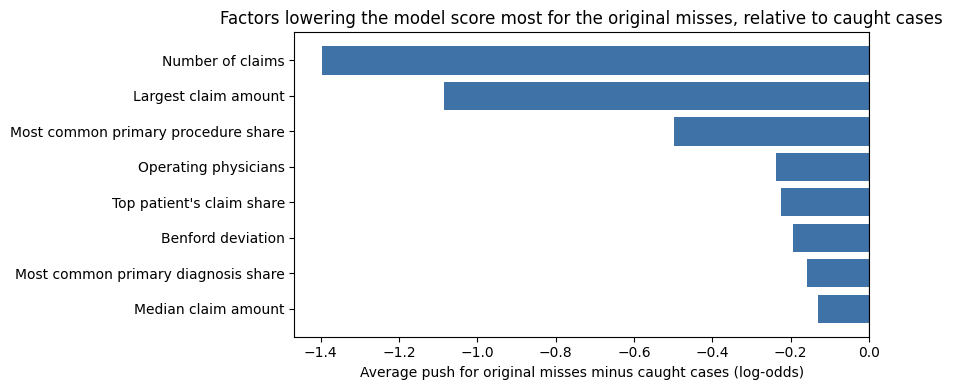

Saved tables to ../reports/error_analysis. They are recomputed identically on each run from the frozen scores.


In [11]:
X = batch.model_input.copy()
X["group"] = scored["group"].to_numpy()
order = ["Still missed", "Recovered by policy", "Caught originally", "Added negative-labelled flag", "Other negative label"]
profiles = profile_table(X, "group", order)
display(profiles)
print("Compare claim volume and inpatient share across groups first: differences in other features may simply follow them.")

C = batch.contributions.copy()
C["group"] = ["Missed originally" if g in ("Recovered by policy", "Still missed") else g for g in scored["group"]]
push = C[C["group"].isin(["Missed originally", "Caught originally"])].groupby("group").mean().T
push["difference"] = push["Missed originally"] - push["Caught originally"]
push = push.sort_values("difference").head(8)
push.index = [glossary.label(f) for f in push.index]
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(push.index[::-1], push["difference"][::-1], color="#3F72A6")
ax.axvline(0, color="#14213D", lw=0.8)
ax.set_xlabel("Average push for original misses minus caught cases (log-odds)")
ax.set_title("Factors lowering the model score most for the original misses, relative to caught cases")
plt.tight_layout(); plt.show()

misses.to_csv(REPORT_DIR / "heldout_original_misses.csv", index=False)
profiles.to_csv(REPORT_DIR / "heldout_group_profiles.csv")
push.to_csv(REPORT_DIR / "heldout_misses_vs_caught_shap.csv")
print(f"Saved tables to {REPORT_DIR}. They are recomputed identically on each run from the frozen scores.")

## Notes for the report

- **The final evaluation is unchanged:** at the frozen threshold, 86 of 101 labelled providers were caught and 15 missed.
- **The alternative policy is exploratory.** It was proposed after that result was known. Its threshold was chosen on out-of-fold validation predictions, committed to git with its rationale, and then evaluated once on the previously used test set. Report that as a supplementary evaluation with its bootstrap ranges, next to the leave-one-fold-out validation range. It is not independent confirmation of an improvement.
- **The cost is workload:** state the share of providers reviewed, the extra reviews per extra labelled provider found, and the additional negative-labelled providers flagged. A lower threshold changes which providers are flagged; it does not improve the model's ranking (average precision is unchanged).
- **Fold tables are descriptive:** the leave-one-fold-out check is still optimistic, because fold models trained partly on each held-out fold. A full assessment of threshold selection needs nested training.
- **Missed-case explanations:** they describe factors lowering the model score, not reasons for fraud. The label is a proxy, not proof.
- **What can guide changes:** only validation analysis (Section 2) should inform feature or model work. Any future change needs a fresh evaluation design.